In [3]:
pip install opencv-python-headless matplotlib numpy pillow scipy scikit-image


   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.9 MB 991.0 kB/s eta 0:00:14
   ---------------------------------------- 0.1/12.9 MB 1.8 MB/s eta 0:00:08
    --------------------------------------- 0.3/12.9 MB 2.0 MB/s eta 0:00:07
   - -------------------------------------- 0.4/12.9 MB 2.1 MB/s eta 0:00:07
   - -------------------------------------- 0.5/12.9 MB 2.2 MB/s eta 0:00:06
   - -------------------------------------- 0.5/12.9 MB 2.2 MB/s eta 0:00:06
   - -------------------------------------- 0.5/12.9 MB 1.6 MB/s eta 0:00:09
   - -------------------------------------- 0.5/12.9 MB 1.4 MB/s eta 0:00:09
   - -------------------------------------- 0.5/12.9 MB 1.3 MB/s eta 0:00:10
   - -------------------------------------- 0.6/12.9 MB 1.3 MB/s eta 0:00:10
   -- ------------------------------------- 0.7/12.9 MB 1.4 MB/s eta 0:00:09
   -- ------------------------------------- 0.7/12.9 MB 1.4 MB/s eta 0:00:09
   -


[notice] A new release of pip is available: 24.0 -> 24.1
[notice] To update, run: python.exe -m pip install --upgrade pip


g:\My Drive\Study\UQS\ENG1901 - Engineering Practice 1\Heat map\300mm45degAng.jpg

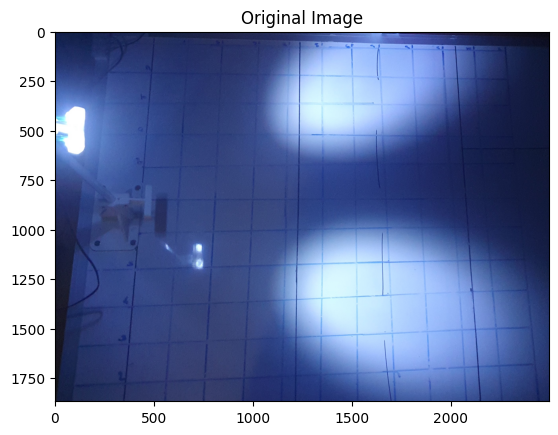

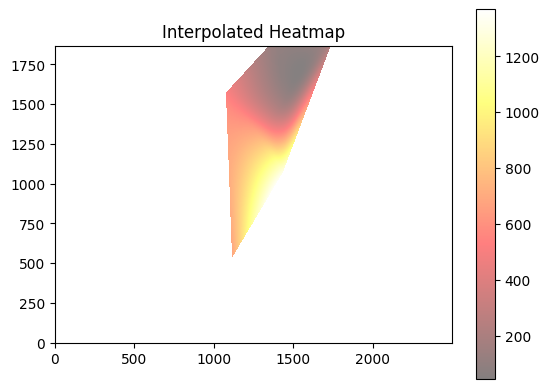

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm45degAng.jpg'
image = cv2.imread(image_path)

# Define the known readings (example data)
# (x, y) coordinates and their respective values
# Coordinates should be relative to the image size
known_points = [
    (1107, 510, 647),
    (1435, 1059, 1332),
    (1438, 1526, 137.3),
    (1068, 1575, 527),
    (1431, 1965, 114.6),
    (1386, 1920, 119.9),
    (1782, 1971, 193.4)
]

# Extract coordinates and values
points = np.array([(x, y) for x, y, v in known_points])
values = np.array([v for x, y, v in known_points])

# Define the grid size based on the image dimensions
grid_x, grid_y = np.mgrid[0:image.shape[1]:1, 0:image.shape[0]:1]

# Perform interpolation
grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

# Plot the original image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.show()

# Plot the interpolated heatmap
plt.imshow(grid_z.T, extent=(0, image.shape[1], 0, image.shape[0]), origin='lower', cmap='hot', alpha=0.5)
plt.colorbar()
plt.title('Interpolated Heatmap')
plt.show()


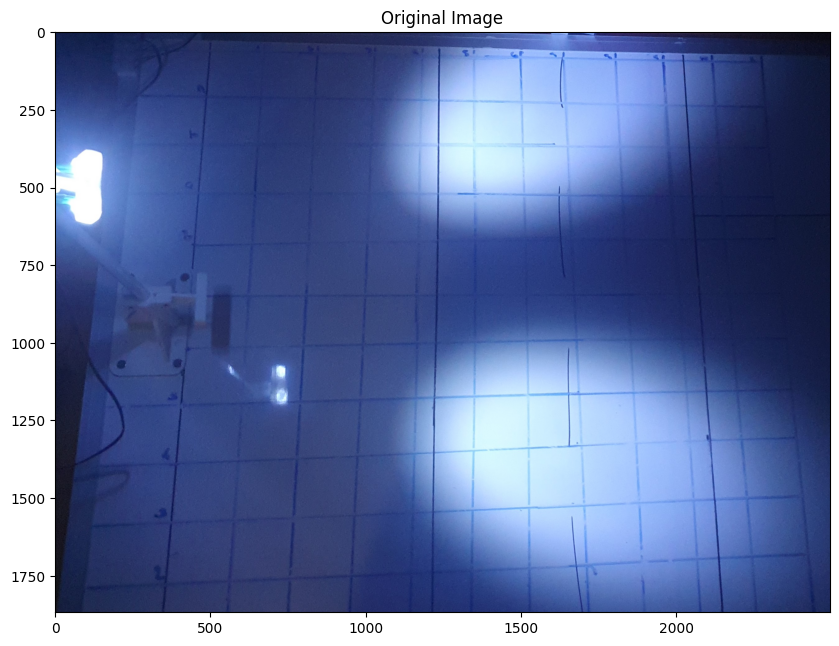

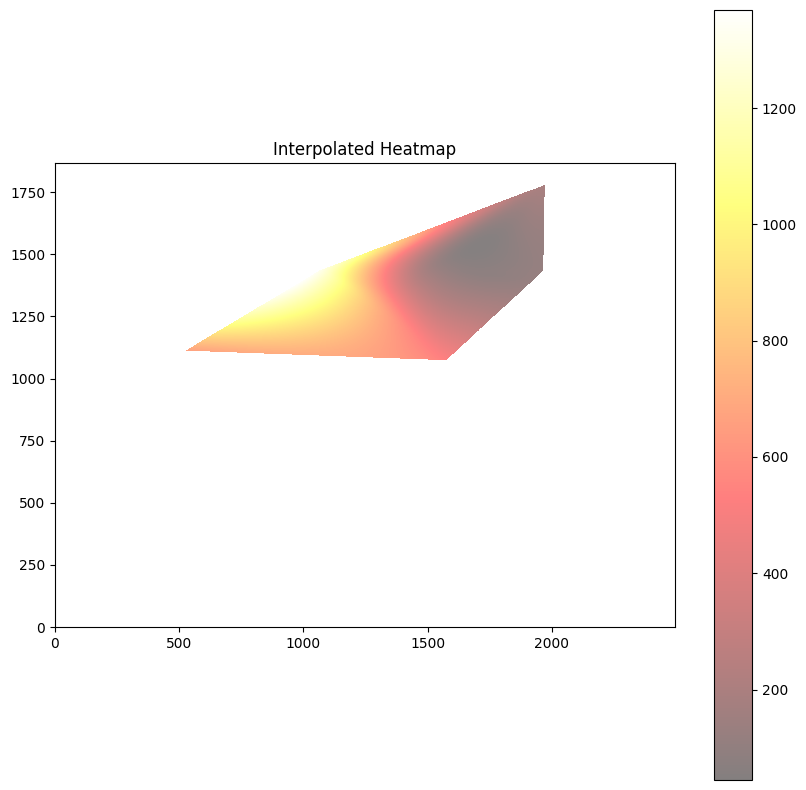

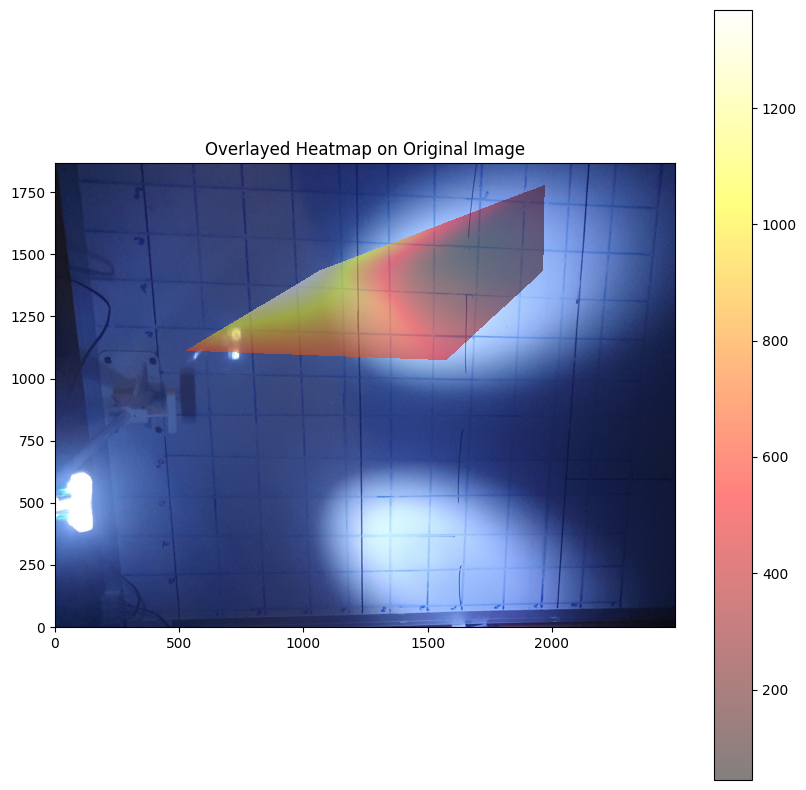

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm45degAng.jpg'
image = cv2.imread(image_path)

# Convert to grayscale if needed
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Define known readings (example data)
# These are the (x, y) coordinates and their respective values
# Replace these with your actual data points and values
known_points = [
    (510, 1107, 647),
    (1059, 1435, 1332),
    (1526, 1438, 137.3),
    (1575, 1068, 527),
    (1965, 1431, 114.6),
    (1920, 1386, 119.9),
    (1971, 1782, 193.4)
]

# Extract coordinates and values
points = np.array([(x, y) for x, y, v in known_points])
values = np.array([v for x, y, v in known_points])

# Define the grid over the entire image
grid_x, grid_y = np.mgrid[0:image.shape[1], 0:image.shape[0]]

# Perform interpolation over the full image grid
grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

# Plot the original image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.show()

# Plot the interpolated heatmap
plt.figure(figsize=(10, 10))
plt.imshow(grid_z.T, extent=(0, image.shape[1], 0, image.shape[0]), origin='lower', cmap='hot', alpha=0.5)
plt.colorbar()
plt.title('Interpolated Heatmap')
plt.show()

# Overlay heatmap on the original image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.imshow(grid_z.T, extent=(0, image.shape[1], 0, image.shape[0]), origin='lower', cmap='hot', alpha=0.5)
plt.title('Overlayed Heatmap on Original Image')
plt.colorbar()
plt.show()

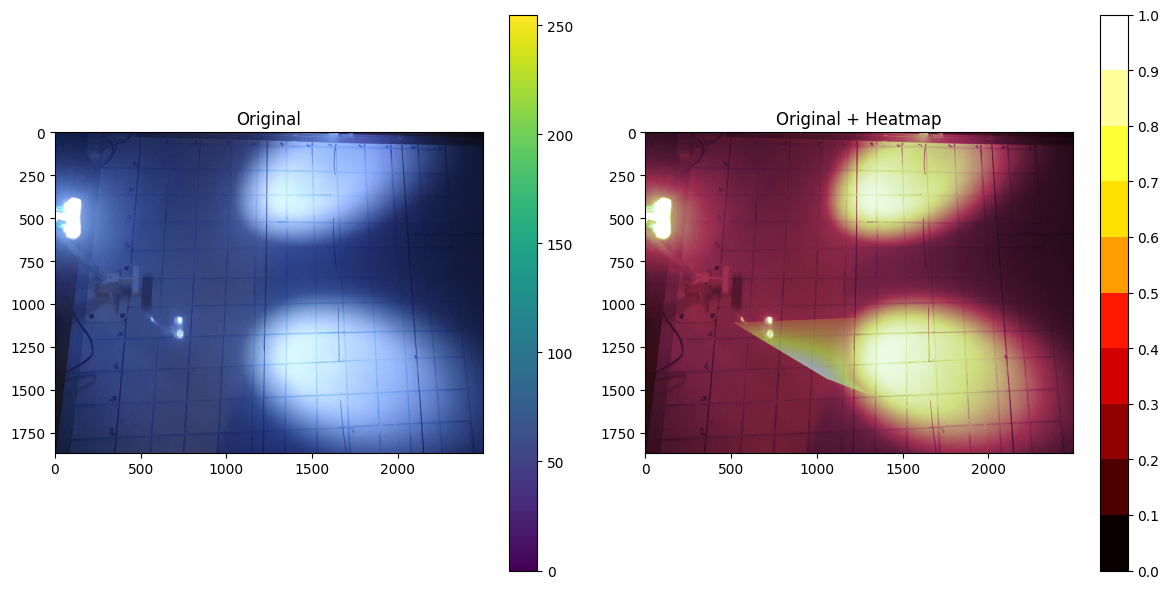

In [7]:
#!/usr/bin/python3
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from skimage.color import rgb2gray
import matplotlib as mpl
from scipy.interpolate import griddata

# Read original image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm45degAng.jpg'
img = io.imread(image_path)

# Convert to grayscale to get the brightness values
gray = rgb2gray(img)

# Normalize the grayscale values to use as heatmap data
normalized_gray = (gray - np.min(gray)) / (np.max(gray) - np.min(gray))

# Define known readings
known_points = [
    (510, 1107, 647),
    (1059, 1435, 1332),
    (1526, 1438, 137.3),
    (1575, 1068, 527),
    (1965, 1431, 114.6),
    (1920, 1386, 119.9),
    (1971, 1782, 193.4)
]

# Extract coordinates and values
points = np.array([(x, y) for x, y, v in known_points])
values = np.array([v for x, y, v in known_points])

# Define the grid over the entire image
grid_x, grid_y = np.mgrid[0:img.shape[1], 0:img.shape[0]]

# Perform interpolation over the full image grid
grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

# Transpose the interpolated grid to match the image dimensions
grid_z = grid_z.T

# Normalize the interpolated values
grid_z_normalized = (grid_z - np.nanmin(grid_z)) / (np.nanmax(grid_z) - np.nanmin(grid_z))
grid_z_normalized = np.nan_to_num(grid_z_normalized)

# Combine the grayscale heatmap with predefined points
combined_heatmap = np.maximum(grid_z_normalized, normalized_gray)

# Plot images
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
ax = axes.ravel()

ax[0].imshow(img)
ax[0].set_title("Original")
fig.colorbar(ax[0].imshow(img), ax=ax[0])

heatmap_img = ax[1].imshow(combined_heatmap, alpha=0.5, cmap='hot')
ax[1].imshow(img)
ax[1].imshow(combined_heatmap, alpha=0.5, cmap='hot')
ax[1].set_title("Original + Heatmap")

# Specific colorbar
norm = mpl.colors.Normalize(vmin=0, vmax=1)
N = 11
cmap = plt.get_cmap('hot', N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax[1], ticks=np.linspace(0, 1, N), boundaries=np.arange(0, 1.1, 0.1))

fig.tight_layout()
plt.show()

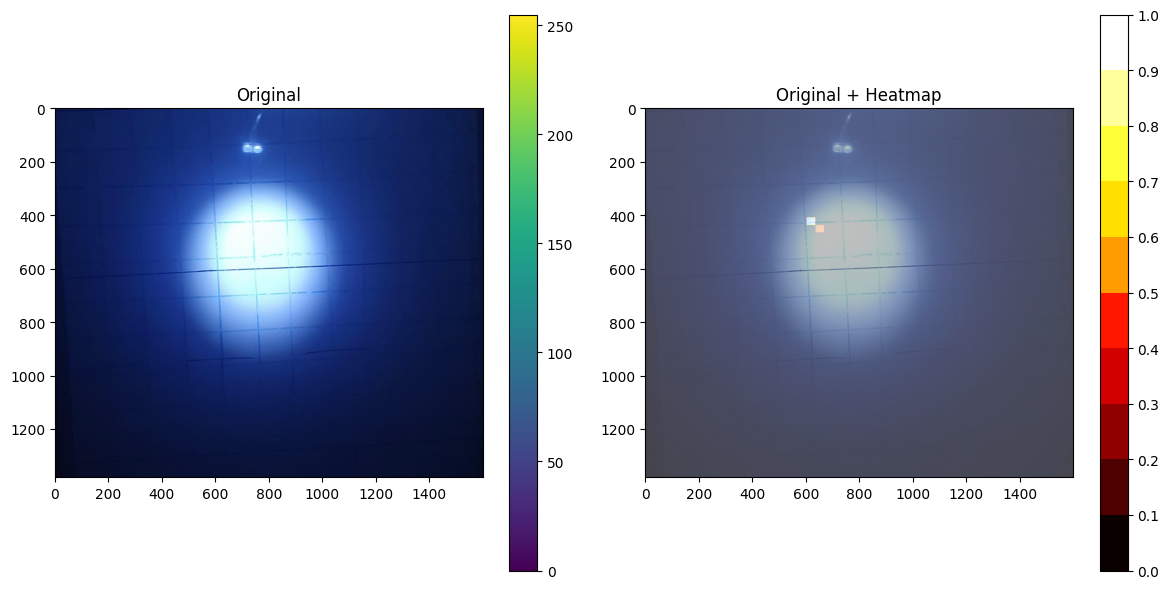

In [36]:
#!/usr/bin/python3
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage import io
from skimage.color import rgb2gray
import matplotlib as mpl
from scipy.interpolate import griddata

# Read original image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm30degStr.jpg'
img = io.imread(image_path)

# Define known readings on the grid
known_points = [
    (822, 624, 25300),
    (670, 456, 20450),
    (516, 350, 536000)
]
# Extract coordinates and values
points = np.array([(x, y) for x, y, v in known_points])
values = np.array([v for x, y, v in known_points])

# Define the grid based on the image size but with fewer points
grid_x, grid_y = np.meshgrid(
    np.linspace(0, img.shape[1] - 1, 50),
    np.linspace(0, img.shape[0] - 1, 50)
)

# Perform interpolation over the grid
grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

# Normalize the interpolated values
grid_z_normalized = (grid_z - np.nanmin(grid_z)) / (np.nanmax(grid_z) - np.nanmin(grid_z))
grid_z_normalized = np.nan_to_num(grid_z_normalized)

# Expand the normalized grid to the size of the image
grid_z_expanded = np.zeros_like(img[:, :, 0], dtype=float)
for i in range(grid_x.shape[0]):
    for j in range(grid_x.shape[1]):
        x_idx = int(grid_x[i, j])
        y_idx = int(grid_y[i, j])
        grid_z_expanded[y_idx, x_idx] = grid_z_normalized[i, j]

# Fill in the gaps in the expanded grid
grid_z_expanded = griddata(
    (grid_x.flatten(), grid_y.flatten()), grid_z_normalized.flatten(),
    (np.mgrid[0:img.shape[1], 0:img.shape[0]][0], np.mgrid[0:img.shape[1], 0:img.shape[0]][1]),
    method='nearest'
)

# Plot images
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
ax = axes.ravel()

ax[0].imshow(img)
ax[0].set_title("Original")
fig.colorbar(ax[0].imshow(img), ax=ax[0])

heatmap_img = ax[1].imshow(grid_z_expanded.T, alpha=0.5, cmap='hot')
ax[1].imshow(img, alpha=0.5)
ax[1].set_title("Original + Heatmap")

# Specific colorbar
norm = mpl.colors.Normalize(vmin=0, vmax=1)
N = 11
cmap = plt.get_cmap('hot', N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax[1], ticks=np.linspace(0, 1, N), boundaries=np.arange(0, 1.1, 0.1))

fig.tight_layout()
plt.show()


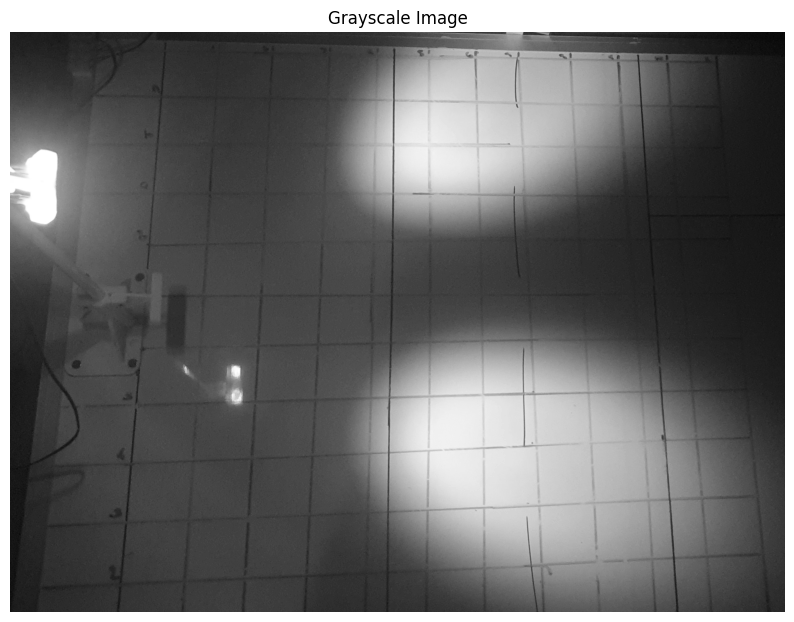

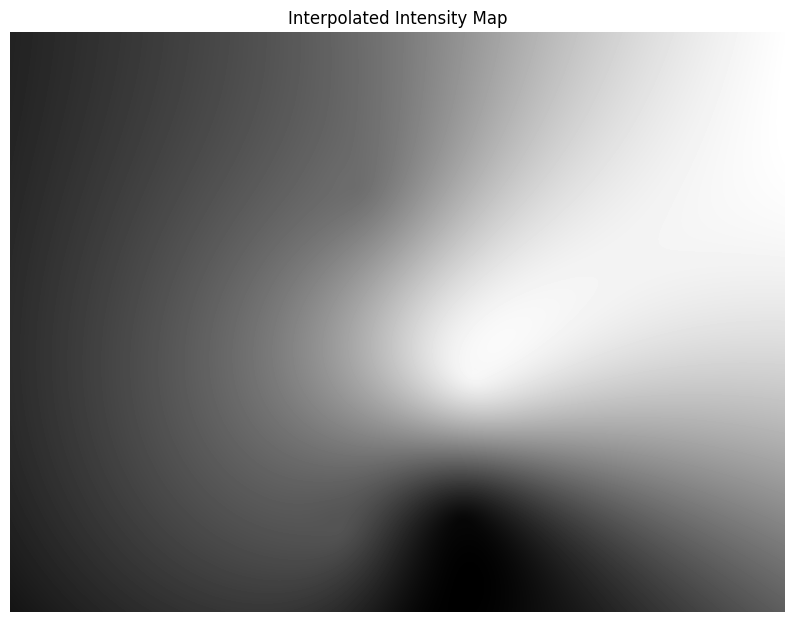

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm45degAng.jpg'
image = cv2.imread(image_path)

# Convert to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.figure(figsize=(10, 10))
plt.title('Grayscale Image')
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

# Define known readings
known_values = [
    (495, 1098, 647),
    (1092, 1497, 1332),
    (1590, 1458, 137.3),
    (1584, 1050, 527),
    (1923, 1377, 114.6),
    (1992, 1761, 193.4)
]

# Parameters
perturbation_radius = 10  # Radius within which to perturb points
num_perturbed_points = 20  # Number of perturbed points to generate per known point

# Generate perturbed points
np.random.seed(0)  # For reproducibility
perturbed_points = []
perturbed_values = []

for x, y, intensity in known_values:
    for _ in range(num_perturbed_points):
        perturbed_x = x + np.random.randint(-perturbation_radius, perturbation_radius + 1)
        perturbed_y = y + np.random.randint(-perturbation_radius, perturbation_radius + 1)
        perturbed_points.append((perturbed_x, perturbed_y))
        perturbed_values.append(intensity)

# Combine original and perturbed points
points = np.array([(x, y) for x, y, _ in known_values] + perturbed_points)
values = np.array([intensity for _, _, intensity in known_values] + perturbed_values)

# Normalize intensity values to grayscale range (0-255)
values = cv2.normalize(values, None, 0, 255, cv2.NORM_MINMAX)

# Create a grid of the same size as the grayscale image
grid_x, grid_y = np.mgrid[0:gray_image.shape[0], 0:gray_image.shape[1]]
grid_points = np.vstack([grid_x.ravel(), grid_y.ravel()]).T

# Perform interpolation using Radial Basis Function (RBF) Interpolator
rbf = RBFInterpolator(points, values, kernel='thin_plate_spline', epsilon=2)
grid_z = rbf(grid_points).reshape(grid_x.shape)

# Handle any NaN values in the interpolated results
grid_z = np.nan_to_num(grid_z, nan=0)
grid_z = cv2.normalize(grid_z, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Display the interpolated intensity map
plt.figure(figsize=(10, 10))
plt.title('Interpolated Intensity Map')
plt.imshow(grid_z, cmap='gray')
plt.axis('off')
plt.show()

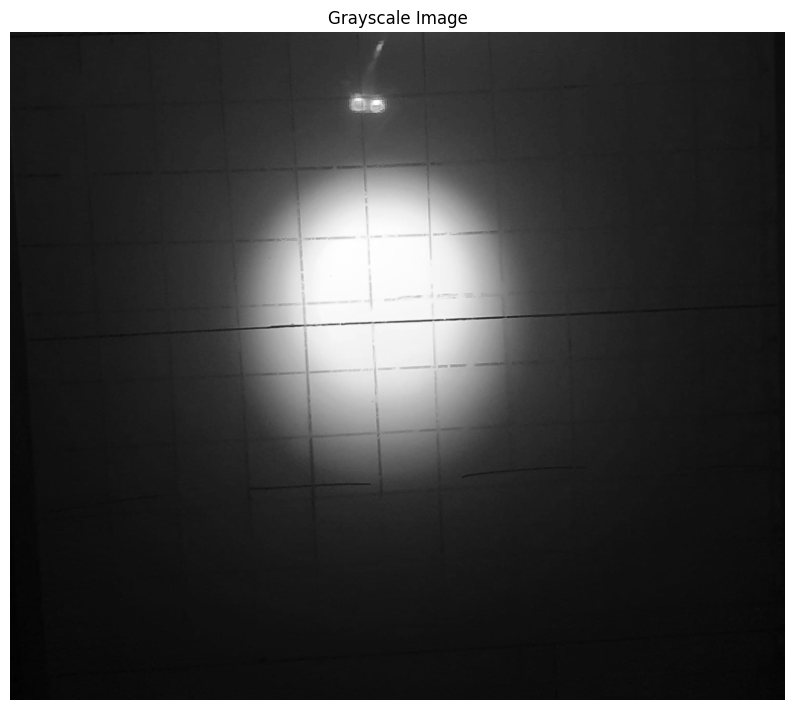

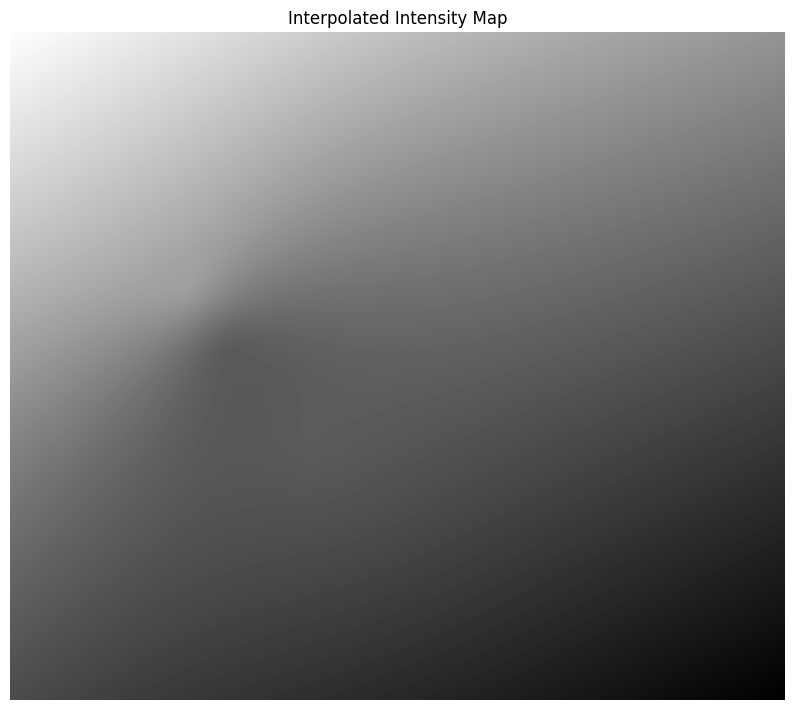

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm30degStr.jpg'
image = cv2.imread(image_path)

# Convert to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.figure(figsize=(10, 10))
plt.title('Grayscale Image')
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

# Define known readings
known_values = [
    (822, 624, 25300),
    (670, 456, 20450),
    (516, 350, 536000)
]

# Parameters
perturbation_radius = 10  # Radius within which to perturb points
num_perturbed_points = 20  # Number of perturbed points to generate per known point

# Generate perturbed points
np.random.seed(0)  # For reproducibility
perturbed_points = []
perturbed_values = []

for x, y, intensity in known_values:
    for _ in range(num_perturbed_points):
        perturbed_x = x + np.random.randint(-perturbation_radius, perturbation_radius + 1)
        perturbed_y = y + np.random.randint(-perturbation_radius, perturbation_radius + 1)
        perturbed_points.append((perturbed_x, perturbed_y))
        perturbed_values.append(intensity)

# Combine original and perturbed points
points = np.array([(x, y) for x, y, _ in known_values] + perturbed_points)
values = np.array([intensity for _, _, intensity in known_values] + perturbed_values)

# Normalize intensity values to grayscale range (0-255)
values = cv2.normalize(values, None, 0, 255, cv2.NORM_MINMAX)

# Create a grid of the same size as the grayscale image
grid_x, grid_y = np.mgrid[0:gray_image.shape[0], 0:gray_image.shape[1]]
grid_points = np.vstack([grid_x.ravel(), grid_y.ravel()]).T

# Perform interpolation using Radial Basis Function (RBF) Interpolator
rbf = RBFInterpolator(points, values, kernel='thin_plate_spline', epsilon=2)
grid_z = rbf(grid_points).reshape(grid_x.shape)

# Handle any NaN values in the interpolated results
grid_z = np.nan_to_num(grid_z, nan=0)
grid_z = cv2.normalize(grid_z, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Display the interpolated intensity map
plt.figure(figsize=(10, 10))
plt.title('Interpolated Intensity Map')
plt.imshow(grid_z, cmap='gray')
plt.axis('off')
plt.show()

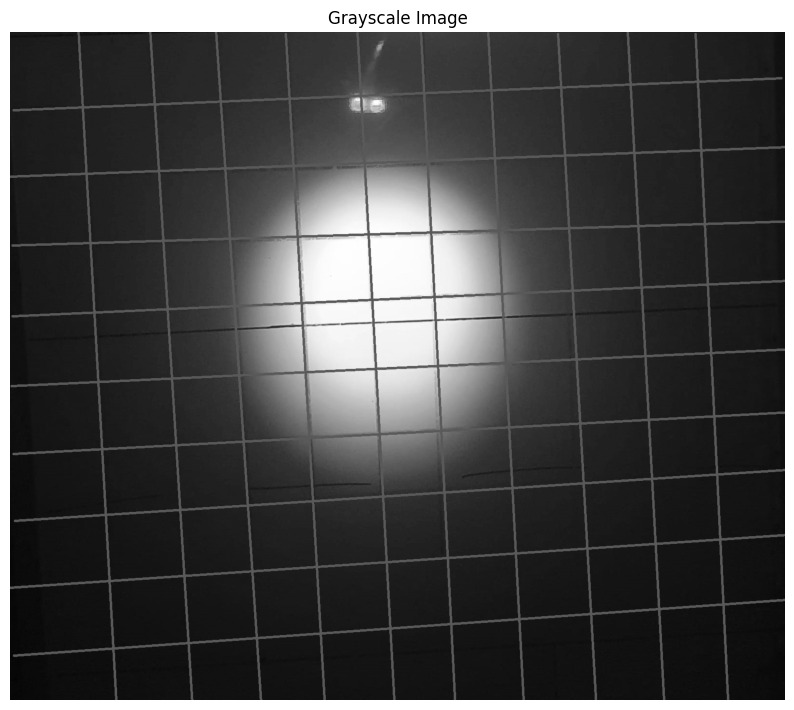

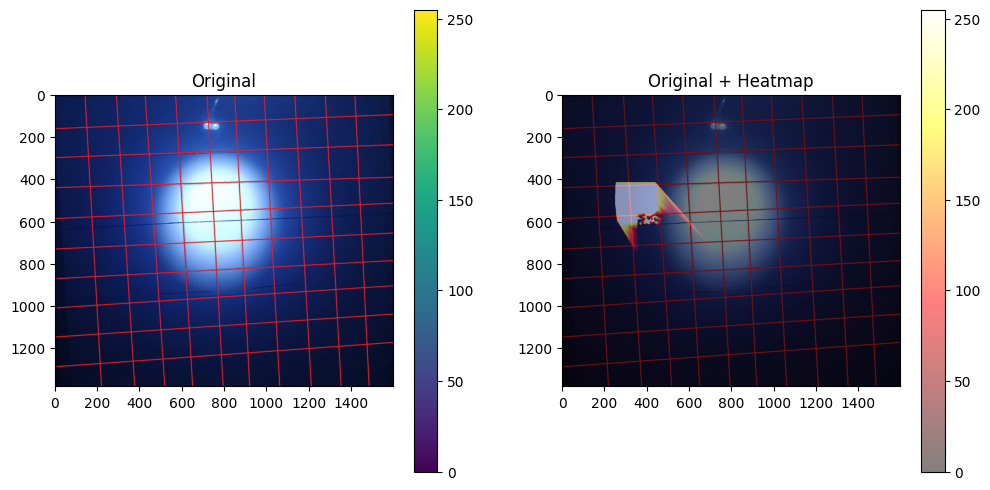

In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

def extract_grid_points(image, color_lower, color_upper):
    # Convert image to HSV color space
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Create a mask for the specified color range
    mask = cv2.inRange(hsv, color_lower, color_upper)

    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    
    # Extract intersection points from the contours
    points = []
    for contour in contours:
        for point in contour:
            points.append(tuple(point[0]))

    return points

def interpolate_light_intensity_on_grid(image_path, known_values, grid_size=50, perturbation_radius=10, num_perturbed_points=100):
    # Load the image
    image = cv2.imread(image_path)

    # Define the red color range for the grid (adjust if necessary)
    red_lower = np.array([0, 100, 100])
    red_upper = np.array([10, 255, 255])

    # Extract grid points
    grid_points = extract_grid_points(image, red_lower, red_upper)

    # Generate perturbed points around known values
    np.random.seed(0)  # For reproducibility
    perturbed_points = []
    perturbed_values = []

    for x, y, intensity in known_values:
        for _ in range(num_perturbed_points):
            perturbed_x = x + np.random.uniform(-perturbation_radius, perturbation_radius)
            perturbed_y = y + np.random.uniform(-perturbation_radius, perturbation_radius)
            if 0 <= perturbed_x < image.shape[1] and 0 <= perturbed_y < image.shape[0]:
                perturbed_points.append((perturbed_x, perturbed_y))
                perturbed_values.append(intensity)

    # Combine original and perturbed points
    points = np.array([(x, y) for x, y, _ in known_values] + perturbed_points)
    values = np.array([intensity for _, _, intensity in known_values] + perturbed_values)

    # Normalize intensity values to grayscale range (0-255)
    values = cv2.normalize(values, None, 0, 255, cv2.NORM_MINMAX)

    # Perform interpolation using griddata for grid points
    grid_points = np.array(grid_points)
    grid_z = griddata(points, values, (grid_points[:, 0], grid_points[:, 1]), method='cubic')

    # Create a new image for the heatmap
    heatmap = np.zeros_like(image[:, :, 0], dtype=np.uint8)

    # Assign interpolated values to the nearest grid points in the heatmap
    for i, (x, y) in enumerate(grid_points):
        if not np.isnan(grid_z[i]):
            heatmap[int(y), int(x)] = grid_z[i]

    # Normalize the heatmap values
    heatmap = cv2.normalize(heatmap, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # Overlay the heatmap on the original image
    heatmap_colored = cv2.applyColorMap(heatmap, cv2.COLORMAP_HOT)
    overlay = cv2.addWeighted(image, 0.7, heatmap_colored, 0.3, 0)

    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.title('Original with Red Grid')
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.colorbar()

    plt.subplot(1, 2, 2)
    plt.title('Original + Heatmap')
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.colorbar()

    plt.show()

# Define known readings
known_values = [
    (822, 624, 25300),
    (670, 456, 20450),
    (516, 350, 536000)
]

# Path to your image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm30degStr.jpg'

# Run the interpolation
interpolate_light_intensity(image_path, known_values)


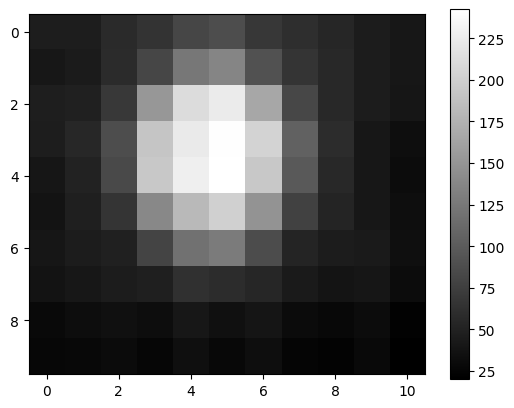

          Col_0     Col_1     Col_2     Col_3     Col_4     Col_5     Col_6  \
Row_0  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_1  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_2  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_3  536000.0  536000.0  536000.0   20450.0  610000.0  311000.0   57000.0   
Row_4  536000.0  536000.0   20450.0   20450.0  510000.0   47400.0   20400.0   
Row_5  536000.0   20450.0   20450.0  610000.0  610000.0   48400.0  235000.0   
Row_6   20450.0   20450.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_7  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_8  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_9  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   

         Col_7     Col_8     Col_9    Col_10  
Row_0  75000.0  480000.0  940000.0  940000.0  
Row_1  75000.0  480000.0  940000.0  

: 

In [97]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm30degStr.jpg'
image = cv2.imread(image_path)

# Manually identified corner points of the red grid in the original image
# These points should be in the order: top-left, top-right, bottom-right, bottom-left
pts_src = np.array([[148, 156], [1420, 104], [1472, 1180], [212, 1274]], dtype='float32')

# Corresponding points in the top-down view (rectified image)
pts_dst = np.array([[0, 0], [110, 0], [110, 100], [0, 100]], dtype='float32')  # 11x10 grid

# Compute the perspective transform matrix
M = cv2.getPerspectiveTransform(pts_src, pts_dst)

# Apply the perspective transformation
corrected_image = cv2.warpPerspective(image, M, (110, 100))

# Convert to grayscale
gray_image = cv2.cvtColor(corrected_image, cv2.COLOR_BGR2GRAY)

# Define grid size (in pixels, after transformation)
grid_size_x = 10  # 110 pixels / 11 columns
grid_size_y = 10  # 100 pixels / 10 rows

# Extract grid dimensions
grid_rows, grid_cols = 10, 11  # 10 rows and 11 columns

# Initialize an array to hold the average intensity values
intensity_matrix = np.zeros((grid_rows, grid_cols))

# Calculate the average intensity for each grid square
for i in range(grid_rows):
    for j in range(grid_cols):
        grid_square = gray_image[i*grid_size_y:(i+1)*grid_size_y, j*grid_size_x:(j+1)*grid_size_x]
        intensity_matrix[i, j] = np.mean(grid_square)

plt.imshow(intensity_matrix, cmap='gray')
plt.colorbar()
plt.show()

# Input known light intensity values (example values)
known_values = {
    (5, 4): 25300,  # Example: grid square (5, 4) has a light intensity of 25300 ohms
    (4, 3): 20450,
    (3, 2): 536000,
    (3, 4): 610000,
    (4, 4): 510000,
    (5, 4): 610000,
    (6, 4): 900000,
    (3, 5): 311000,
    (4, 5): 47400,
    (5, 5): 48400,
    (6, 5): 126000,
    (3, 6): 57000,
    (4, 6): 20400,
    (5, 6): 235000,
    (6, 6): 39600,
    (3, 7): 75000,
    (4, 7): 22600,
    (5, 7): 24150,
    (6, 7): 40200,
    (3, 8): 480000,
    (4, 8): 108000,
    (5, 8): 81400,
    (6, 8): 151700,
    (3, 9): 940000,
    (4, 9): 840000,
    (5, 9): 860000,
    (6, 9): 870000
}

# Prepare data for interpolation
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid for interpolation
grid_x, grid_y = np.mgrid[0:grid_rows, 0:grid_cols]

# Interpolate the unknown values using nearest-neighbor method
intensity_estimates = griddata(points, values, (grid_x, grid_y), method='nearest')

# Fill known values into the intensity estimates
for point, value in known_values.items():
    intensity_estimates[point] = value

# Document the results in a DataFrame
intensity_df = pd.DataFrame(intensity_estimates, columns=[f'Col_{i}' for i in range(grid_cols)], index=[f'Row_{i}' for i in range(grid_rows)])

# Display the DataFrame
print(intensity_df)

# Optionally, save the DataFrame to a CSV file
intensity_df.to_csv('light_intensity_estimates.csv')

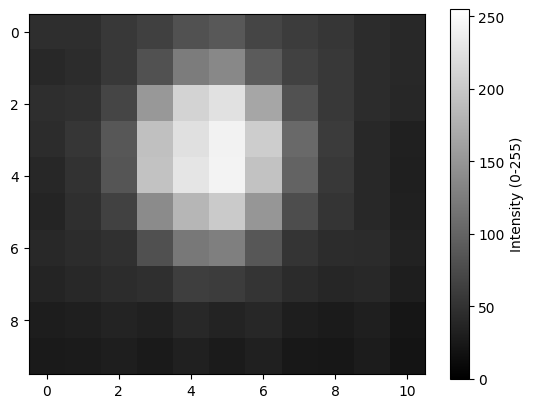

          Col_0     Col_1     Col_2     Col_3     Col_4     Col_5     Col_6  \
Row_0  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_1  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_2  536000.0  536000.0  536000.0  536000.0  610000.0  311000.0   57000.0   
Row_3  536000.0  536000.0  536000.0   20450.0  610000.0  311000.0   57000.0   
Row_4  536000.0  536000.0   20450.0   20450.0  510000.0   47400.0   20400.0   
Row_5  536000.0   20450.0   20450.0  610000.0  610000.0   48400.0  235000.0   
Row_6   20450.0   20450.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_7  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_8  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   
Row_9  900000.0  900000.0  900000.0  900000.0  900000.0  126000.0   39600.0   

         Col_7     Col_8     Col_9    Col_10  
Row_0  75000.0  480000.0  940000.0  940000.0  
Row_1  75000.0  480000.0  940000.0  

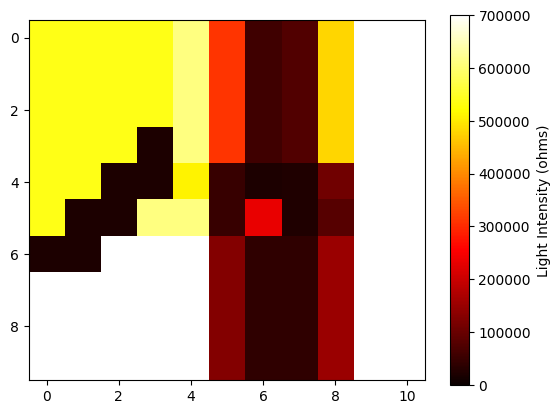

In [96]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm30degStr.jpg'
image = cv2.imread(image_path)

# Manually identified corner points of the red grid in the original image
# These points should be in the order: top-left, top-right, bottom-right, bottom-left
pts_src = np.array([[148, 156], [1420, 104], [1472, 1180], [212, 1274]], dtype='float32')

# Corresponding points in the top-down view (rectified image)
pts_dst = np.array([[0, 0], [110, 0], [110, 100], [0, 100]], dtype='float32')  # 11x10 grid

# Compute the perspective transform matrix
M = cv2.getPerspectiveTransform(pts_src, pts_dst)

# Apply the perspective transformation
corrected_image = cv2.warpPerspective(image, M, (110, 100))

# Convert to grayscale
gray_image = cv2.cvtColor(corrected_image, cv2.COLOR_BGR2GRAY)

# Define grid size (in pixels, after transformation)
grid_size_x = 10  # 110 pixels / 11 columns
grid_size_y = 10  # 100 pixels / 10 rows

# Extract grid dimensions
grid_rows, grid_cols = 10, 11  # 10 rows and 11 columns

# Initialize an array to hold the average intensity values
intensity_matrix = np.zeros((grid_rows, grid_cols))

# Calculate the average intensity for each grid square
for i in range(grid_rows):
    for j in range(grid_cols):
        grid_square = gray_image[i*grid_size_y:(i+1)*grid_size_y, j*grid_size_x:(j+1)*grid_size_x]
        intensity_matrix[i, j] = np.mean(grid_square)

# Display the grayscale intensity matrix with adjusted scale
plt.imshow(intensity_matrix, cmap='gray', vmin=0, vmax=255)
plt.colorbar(label='Intensity (0-255)')
plt.show()

# Input known light intensity values (example values)
known_values = {
    (5, 4): 25300,  # Example: grid square (5, 4) has a light intensity of 25300 ohms
    (4, 3): 20450,
    (3, 2): 536000,
    (3, 4): 610000,
    (4, 4): 510000,
    (5, 4): 610000,
    (6, 4): 900000,
    (3, 5): 311000,
    (4, 5): 47400,
    (5, 5): 48400,
    (6, 5): 126000,
    (3, 6): 57000,
    (4, 6): 20400,
    (5, 6): 235000,
    (6, 6): 39600,
    (3, 7): 75000,
    (4, 7): 22600,
    (5, 7): 24150,
    (6, 7): 40200,
    (3, 8): 480000,
    (4, 8): 108000,
    (5, 8): 81400,
    (6, 8): 151700,
    (3, 9): 940000,
    (4, 9): 840000,
    (5, 9): 860000,
    (6, 9): 870000
}

# Prepare data for interpolation
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid for interpolation
grid_x, grid_y = np.mgrid[0:grid_rows, 0:grid_cols]

# Interpolate the unknown values using nearest-neighbor method
intensity_estimates = griddata(points, values, (grid_x, grid_y), method='nearest')

# Fill known values into the intensity estimates
for point, value in known_values.items():
    intensity_estimates[point] = value

# Document the results in a DataFrame
intensity_df = pd.DataFrame(intensity_estimates, columns=[f'Col_{i}' for i in range(grid_cols)], index=[f'Row_{i}' for i in range(grid_rows)])

# Display the DataFrame
print(intensity_df)

# Optionally, save the DataFrame to a CSV file
intensity_df.to_csv('light_intensity_estimates.csv')

# Display the interpolated intensity values with the correct scale
plt.imshow(intensity_estimates, cmap='hot', interpolation='nearest', vmin=0, vmax=700000)
plt.colorbar(label='Light Intensity (ohms)')
plt.show()


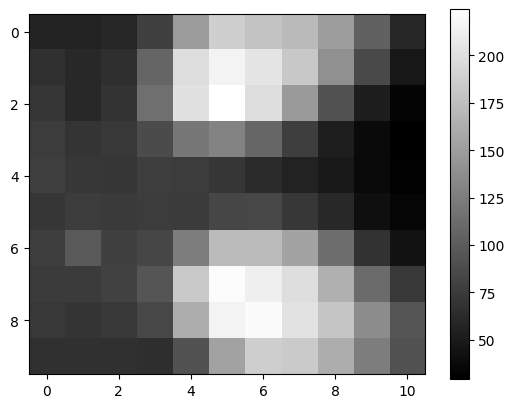

          Col_0     Col_1     Col_2     Col_3     Col_4     Col_5     Col_6  \
Row_0   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   
Row_1   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   
Row_2   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   
Row_3   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0   
Row_4   64700.0   64700.0   64700.0   64700.0   64700.0   64700.0  133200.0   
Row_5  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0   
Row_6  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0   
Row_7  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0   
Row_8  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0   
Row_9  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0  527000.0   

          Col_7     Col_8     Col_9    Col_10  
Row_0   64700.0   64700.0   64700.0   64700.0  
Row_1   64700.0   64700.0   64700.

In [64]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/300mm45degAng.jpg'
image = cv2.imread(image_path)

# Manually identified corner points of the red grid in the original image
# These points should be in the order: top-left, top-right, bottom-right, bottom-left
pts_src = np.array([[168, 33], [1959, 84], [2103, 1662], [21, 1758]], dtype='float32')

# Corresponding points in the top-down view (rectified image)
pts_dst = np.array([[0, 0], [110, 0], [110, 100], [0, 100]], dtype='float32')  # 11x10 grid

# Compute the perspective transform matrix
M = cv2.getPerspectiveTransform(pts_src, pts_dst)

# Apply the perspective transformation
corrected_image = cv2.warpPerspective(image, M, (110, 100))

# Convert to grayscale
gray_image = cv2.cvtColor(corrected_image, cv2.COLOR_BGR2GRAY)

# Define grid size (in pixels, after transformation)
grid_size_x = 10  # 110 pixels / 11 columns
grid_size_y = 10  # 100 pixels / 10 rows

# Extract grid dimensions
grid_rows, grid_cols = 10, 11  # 10 rows and 11 columns

# Initialize an array to hold the average intensity values
intensity_matrix = np.zeros((grid_rows, grid_cols))

# Calculate the average intensity for each grid square
for i in range(grid_rows):
    for j in range(grid_cols):
        grid_square = gray_image[i*grid_size_y:(i+1)*grid_size_y, j*grid_size_x:(j+1)*grid_size_x]
        intensity_matrix[i, j] = np.mean(grid_square)

plt.imshow(intensity_matrix, cmap='gray')
plt.colorbar()
plt.show()

# Input known light intensity values (example values)
known_values = {
    (1, 7): 64700,  # Example: grid square (2, 3) has a light intensity of 50 ohms
    (4, 9): 133200,
    (7, 9): 137300,
    (7, 7): 527000,
    (9, 9): 114800,
    (9,10): 193400
}


# Prepare data for interpolation
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid for interpolation
grid_x, grid_y = np.mgrid[0:grid_rows, 0:grid_cols]

# Interpolate the unknown values using nearest-neighbor method
intensity_estimates = griddata(points, values, (grid_x, grid_y), method='nearest')

# Fill known values into the intensity estimates
for point, value in known_values.items():
    intensity_estimates[point] = value

# Document the results in a DataFrame
intensity_df = pd.DataFrame(intensity_estimates, columns=[f'Col_{i}' for i in range(grid_cols)], index=[f'Row_{i}' for i in range(grid_rows)])

# Display the DataFrame
print(intensity_df)

# Optionally, save the DataFrame to a CSV file
intensity_df.to_csv('light_intensity_estimates.csv')

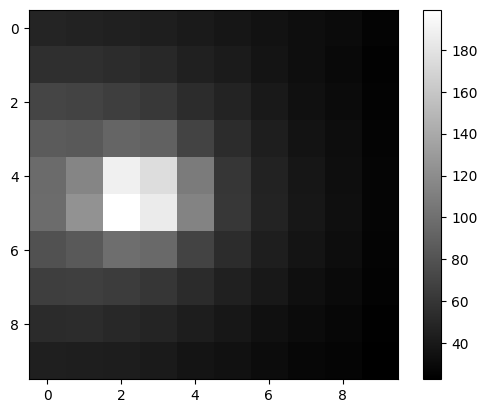

          Col_0     Col_1     Col_2     Col_3     Col_4     Col_5     Col_6  \
Row_0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   
Row_1   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   
Row_2   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   
Row_3   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   
Row_4   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   12230.0   
Row_5   12230.0   12230.0   12230.0   12230.0   12230.0  670000.0  670000.0   
Row_6   12230.0   12230.0   12230.0  670000.0  670000.0  670000.0  670000.0   
Row_7   12230.0  670000.0  670000.0  670000.0  670000.0  670000.0  670000.0   
Row_8  670000.0  670000.0  670000.0  670000.0  670000.0  670000.0  670000.0   
Row_9  670000.0  670000.0  670000.0  670000.0  670000.0  670000.0  670000.0   

               Col_7          Col_8     Col_9  
Row_0   12230.000000  379000.000000  379000.0  
Row_1   12230.000000  379000.00000

In [78]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/200mm30degStr.jpg'
image = cv2.imread(image_path)

# Manually identified corner points of the red grid in the original image
# These points should be in the order: top-left, top-right, bottom-right, bottom-left
pts_src = np.array([[150, 126], [1680, 138], [1746, 1899], [144, 1977]], dtype='float32')

# Corresponding points in the top-down view (rectified image)
pts_dst = np.array([[0, 0], [1100, 0], [1100, 1000], [0, 1000]], dtype='float32')  # 1100x1000 pixels

# Compute the perspective transform matrix
M = cv2.getPerspectiveTransform(pts_src, pts_dst)

# Apply the perspective transformation
corrected_image = cv2.warpPerspective(image, M, (1100, 1000))

# Convert to grayscale
gray_image = cv2.cvtColor(corrected_image, cv2.COLOR_BGR2GRAY)

# Define grid size (in pixels, after transformation)
grid_size_x = 110  # 1100 pixels / 10 columns
grid_size_y = 100  # 1000 pixels / 10 rows

# Extract grid dimensions
grid_rows, grid_cols = 10, 10  # 10 rows and 10 columns

# Initialize an array to hold the average intensity values
intensity_matrix = np.zeros((grid_rows, grid_cols))

# Calculate the average intensity for each grid square
for i in range(grid_rows):
    for j in range(grid_cols):
        grid_square = gray_image[i*grid_size_y:(i+1)*grid_size_y, j*grid_size_x:(j+1)*grid_size_x]
        intensity_matrix[i, j] = np.mean(grid_square)

plt.imshow(intensity_matrix, cmap='gray')
plt.colorbar()
plt.show()

# Input known light intensity values (example values)
known_values = {
    (3, 6): 12230,  # Example: grid square (3, 6) has a light intensity of 12230 units
    (3, 9): 379000,
    (5, 7): 670000
}

# Prepare data for interpolation
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid for interpolation
grid_x, grid_y = np.mgrid[0:grid_rows, 0:grid_cols]


# Calculate the ratio of known values to their corresponding grid intensities
ratios = {k: known_values[k] / intensity_matrix[k] for k in known_values}

# Adjust the intensity matrix using the computed ratios
adjusted_intensity_matrix = np.copy(intensity_matrix)

for k, ratio in ratios.items():
    adjusted_intensity_matrix *= ratio / np.mean(adjusted_intensity_matrix[k])

# Interpolate the unknown values using cubic method
intensity_estimates = griddata(points, values, (grid_x, grid_y), method='cubic')

# If any NaN values remain, fill them using linear interpolation
if np.isnan(intensity_estimates).any():
    linear_intensity_estimates = griddata(points, values, (grid_x, grid_y), method='linear')
    intensity_estimates = np.where(np.isnan(intensity_estimates), linear_intensity_estimates, intensity_estimates)

# If any NaN values still remain, fill them using nearest interpolation
if np.isnan(intensity_estimates).any():
    nearest_intensity_estimates = griddata(points, values, (grid_x, grid_y), method='nearest')
    intensity_estimates = np.where(np.isnan(intensity_estimates), nearest_intensity_estimates, intensity_estimates)

# Document the results in a DataFrame
intensity_df = pd.DataFrame(intensity_estimates, columns=[f'Col_{i}' for i in range(grid_cols)], index=[f'Row_{i}' for i in range(grid_rows)])

# Display the DataFrame
print(intensity_df)

# Optionally, save the DataFrame to a CSV file
intensity_df.to_csv('light_intensity_estimates.csv')

               Col_0          Col_1          Col_2          Col_3  \
Row_0  423740.185604  423740.185604  423740.185604  423740.185604   
Row_1  423740.185604  423740.185604  423740.185604  423740.185604   
Row_2  423740.185604  423740.185604  423740.185604  423740.185604   
Row_3  423740.185604  423740.185604  423740.185604  423740.185604   
Row_4  423740.185604  423740.185604  423740.185604  423740.185604   
Row_5  423740.185604  423740.185604  423740.185604  423740.185604   
Row_6  423740.185604  423740.185604  423740.185604  231185.205370   
Row_7  423740.185604  231185.205370  231185.205370  231185.205370   
Row_8  231185.205370  231185.205370  231185.205370  231185.205370   
Row_9  231185.205370  231185.205370  231185.205370  231185.205370   

               Col_4          Col_5          Col_6         Col_7  \
Row_0  423740.185604  423740.185604  423740.185604  4.237402e+05   
Row_1  423740.185604  423740.185604  423740.185604  4.237402e+05   
Row_2  423740.185604  423740.185604 

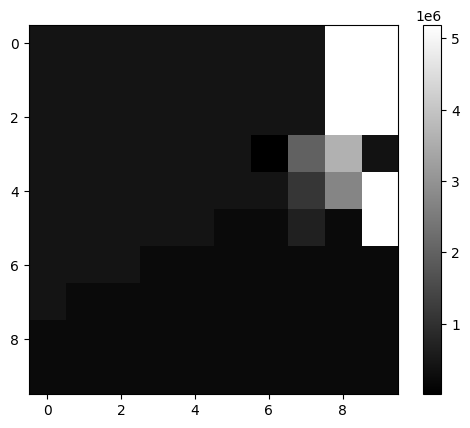

In [83]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Load the image
image_path = 'g:/My Drive/Study/UQS/ENG1901 - Engineering Practice 1/Heat map/200mm30degStr_rev.png'
image = cv2.imread(image_path)

# Convert to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Define grid size (in pixels)
grid_size_x = gray_image.shape[1] // 10  # 10 columns
grid_size_y = gray_image.shape[0] // 10  # 10 rows

# Extract grid dimensions
grid_rows, grid_cols = 10, 10  # 10 rows and 10 columns

# Initialize an array to hold the average intensity values
intensity_matrix = np.zeros((grid_rows, grid_cols))

# Calculate the average intensity for each grid square
for i in range(grid_rows):
    for j in range(grid_cols):
        grid_square = gray_image[i*grid_size_y:(i+1)*grid_size_y, j*grid_size_x:(j+1)*grid_size_x]
        intensity_matrix[i, j] = np.mean(grid_square)

# Normalize the intensity matrix
normalized_intensity_matrix = intensity_matrix / np.max(intensity_matrix)

# Input known light intensity values (example values)
known_values = {
    (3, 6): 12230,  # Example: grid square (3, 6) has a light intensity of 12230 units
    (3, 9): 379000,
    (5, 7): 670000
}

# Prepare data for interpolation
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid for interpolation
grid_x, grid_y = np.mgrid[0:grid_rows, 0:grid_cols]

# Interpolate the normalized values using cubic method
normalized_estimates = griddata(points, normalized_intensity_matrix[points[:,0], points[:,1]], (grid_x, grid_y), method='cubic')

# If any NaN values remain, fill them using linear interpolation
if np.isnan(normalized_estimates).any():
    linear_normalized_estimates = griddata(points, normalized_intensity_matrix[points[:,0], points[:,1]], (grid_x, grid_y), method='linear')
    normalized_estimates = np.where(np.isnan(normalized_estimates), linear_normalized_estimates, normalized_estimates)

# If any NaN values still remain, fill them using nearest interpolation
if np.isnan(normalized_estimates).any():
    nearest_normalized_estimates = griddata(points, normalized_intensity_matrix[points[:,0], points[:,1]], (grid_x, grid_y), method='nearest')
    normalized_estimates = np.where(np.isnan(normalized_estimates), nearest_normalized_estimates, normalized_estimates)

# Scale the normalized estimates to actual intensity values
scaling_factors = {k: known_values[k] / normalized_intensity_matrix[k] for k in known_values}
scaled_intensity_matrix = normalized_estimates * np.mean(list(scaling_factors.values()))

# Fill known values into the scaled intensity estimates
for point, value in known_values.items():
    scaled_intensity_matrix[point] = value

# Document the results in a DataFrame
intensity_df = pd.DataFrame(scaled_intensity_matrix, columns=[f'Col_{i}' for i in range(grid_cols)], index=[f'Row_{i}' for i in range(grid_rows)])

# Display the DataFrame
print(intensity_df)

# Optionally, save the DataFrame to a CSV file
intensity_df.to_csv('light_intensity_estimates.csv')

# Display the adjusted intensity matrix as an image
plt.imshow(scaled_intensity_matrix, cmap='gray')
plt.colorbar()
plt.show()

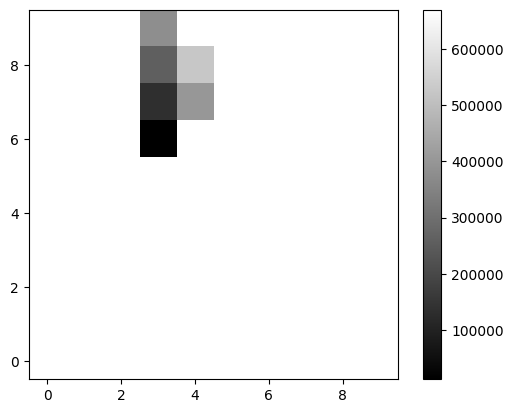

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Known values
known_values = {
    (3, 6): 12230,
    (3, 9): 379000,
    (5, 7): 670000
}

# Grid size
grid_size = (10, 10)

# Extract coordinates and values from known_values
points = np.array(list(known_values.keys()))
values = np.array(list(known_values.values()))

# Create a grid of points where we want to interpolate values
grid_x, grid_y = np.meshgrid(np.arange(grid_size[0]), np.arange(grid_size[1]))

# Interpolate the grid using known points
grid_z = griddata(points, values, (grid_x, grid_y), method='linear')

# Plot the result
plt.imshow(grid_z, origin='lower', cmap='gray')
plt.colorbar()
plt.show()
